# Bout discretisation

From the tracking at 30 frames per second to the table of bouts that every model is trained on
(`data/bouts_clean.csv`). The input is one table per fish at 30 fps (`data/frames/`, see `data/README.md`): the
fish's position and orientation and the position of every dot, in every frame.

In [1]:
import io

import numpy as np
import pandas as pd
from figures import data_figures, fig_bout_trajectory
from twin import cleaning, paths
from twin import segment_bouts as SB
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

## The 30 fps tables
Fish 0's table: frame, stimulus label, the fish's position (camera px) and orientation, and every dot's position.

In [2]:
frames_raw = [(int(p.stem.split("_f")[-1].split("_")[0]), pd.read_csv(p))
              for p in sorted(paths.FRAMES.glob("*_transformed_abs.csv"))]
print(f"{len(frames_raw)} fish, {len(frames_raw[0][1]):,} frames each ({len(frames_raw[0][1]) / 30 / 60:.0f} min)")
frames_raw[0][1].dropna().head()

15 fish, 313,500 frames each (174 min)


,frame,stimulus,f0_x,f0_y,f0_ori,d0_x,d0_y,d0_stim,d1_x,d1_y,d1_stim,d2_x,d2_y,d2_stim,d3_x,d3_y,d3_stim,d4_x,d4_y,d4_stim,d5_x,d5_y,d5_stim,d6_x,d6_y,d6_stim,d7_x,d7_y,d7_stim
1500,1500,CLsemi1800_g4-0_s3.5-3.5,166.0,226.0,3.049185,171.323132,155.772777,CLsemi1800_g4-0_s3.5-3.5,169.566389,139.202384,CLsemi1800_g4-0_s3.5-3.5,185.651694,156.47208,CLsemi1800_g4-0_s3.5-3.5,144.289881,176.669752,CLsemi1800_g4-0_s3.5-3.5,166.0,226.0,none,166.0,226.0,none,166.0,226.0,none,166.0,226.0,none
1501,1501,CLsemi1800_g4-0_s3.5-3.5,167.0,226.0,3.117185,171.323132,155.772777,CLsemi1800_g4-0_s3.5-3.5,169.566389,139.202384,CLsemi1800_g4-0_s3.5-3.5,185.651694,156.47208,CLsemi1800_g4-0_s3.5-3.5,144.289881,176.669752,CLsemi1800_g4-0_s3.5-3.5,166.0,226.0,none,166.0,226.0,none,166.0,226.0,none,166.0,226.0,none
1502,1502,CLsemi1800_g4-0_s3.5-3.5,167.0,226.0,3.105185,171.323132,155.772777,CLsemi1800_g4-0_s3.5-3.5,169.566389,139.202384,CLsemi1800_g4-0_s3.5-3.5,185.651694,156.47208,CLsemi1800_g4-0_s3.5-3.5,136.578511,176.978945,CLsemi1800_g4-0_s3.5-3.5,166.0,226.0,none,166.0,226.0,none,166.0,226.0,none,166.0,226.0,none
1503,1503,CLsemi1800_g4-0_s3.5-3.5,167.0,226.0,3.081185,171.323132,155.772777,CLsemi1800_g4-0_s3.5-3.5,169.566389,139.202384,CLsemi1800_g4-0_s3.5-3.5,185.651694,156.47208,CLsemi1800_g4-0_s3.5-3.5,136.578511,176.978945,CLsemi1800_g4-0_s3.5-3.5,166.0,226.0,none,166.0,226.0,none,166.0,226.0,none,166.0,226.0,none
1504,1504,CLsemi1800_g4-0_s3.5-3.5,167.0,226.0,3.108185,171.323132,155.772777,CLsemi1800_g4-0_s3.5-3.5,169.566389,139.202384,CLsemi1800_g4-0_s3.5-3.5,185.651694,156.47208,CLsemi1800_g4-0_s3.5-3.5,136.578511,176.978945,CLsemi1800_g4-0_s3.5-3.5,166.0,226.0,none,166.0,226.0,none,166.0,226.0,none,166.0,226.0,none


## Bout detection (Figure fig:detection)
A bout is a peak of the smoothed swimming speed above its mean plus one SD, at least 0.4 s after the previous one,
whose displacement around the peak is between 0.3 and 25 mm; its onset is the speed minimum before the peak.

  detection: 2 of 8 onsets moved by the snap


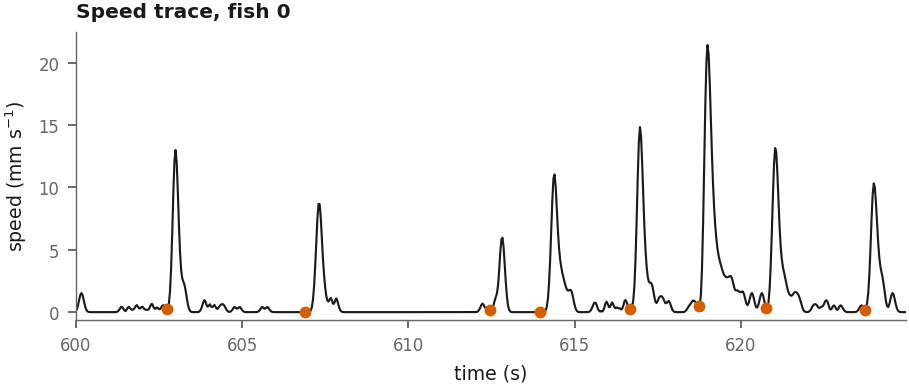

In [3]:
data_figures.fig_detection(data_figures.load())

## From the trajectory to bouts (Figure fig:bouttraj)

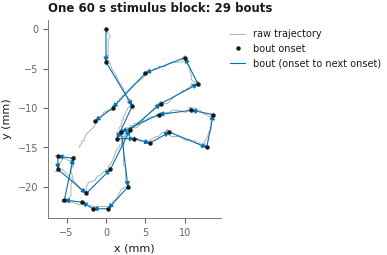

In [4]:
fig_bout_trajectory.main()

## Every fish segmented
The segmenter on the 30 fps tables gives the bout table `data/bouts_GsizeMotionSingle.csv`. Turn, displacement and
interval of a bout are measured from its onset to the next one.

In [5]:
raw = cleaning.segment(frames_raw).drop(columns=["near_wall", "v_mm_s"])
archived = pd.read_csv(paths.BOUTS_RAW)
cols = [c for c in archived.columns if c in raw.columns]
print(f"{len(raw):,} bouts, {raw.fish_id.nunique()} fish")
print("identical to data/bouts_GsizeMotionSingle.csv:",
      len(raw) == len(archived) and all(np.allclose(raw[c], archived[c], equal_nan=True)
                                        if pd.api.types.is_numeric_dtype(archived[c])
                                        else (raw[c].astype(str) == archived[c].astype(str)).all() for c in cols))

71,933 bouts, 15 fish
identical to data/bouts_GsizeMotionSingle.csv: True


## Step 1: tracking excursions repaired
The tracker sometimes loses the fish for one to five frames and reports it elsewhere, generally at the dish edge,
which the speed smoothing turns into impossibly fast bouts. Such excursions (a step over 100 mm/s that comes back
within five frames) are bridged by linear interpolation.

In [6]:
frames, report, repaired = cleaning.repair_frames()
print(f"repaired {report.repaired.sum()} of {report.frames.sum():,} frames")
report

repaired 72 of 4,699,506 frames


,frames,repaired,pct,max_step_before,max_step_after,over_100mm_s_before,over_100mm_s_after
fish,,,,,,,
0,313355,0,0.0000,28.6,28.6,20,20
10,313380,18,0.0057,43.0,43.0,47,30
11,313380,11,0.0035,91.2,27.5,27,17
12,313380,0,0.0000,28.3,28.3,28,28
13,313380,7,0.0022,56.7,56.7,47,40
14,313319,11,0.0035,34.5,34.5,41,37
1,313380,3,0.0010,29.4,29.4,45,43
2,313380,8,0.0026,27.8,27.8,37,34
3,313380,0,0.0000,31.1,31.1,29,29


## Step 2: re-segmented, gaps flagged, model columns added
A bout whose interval exceeds 10 s spans a quiescent gap: its step and turn are measured across the gap. A bout is
*active* if neither its own leg nor the previous one spans a gap; models are fitted on active bouts only. Then the
block clocks, the runs between gaps and the lags within a run, the dot and wall bearings in the travel frame, and the
position of every dot at each onset.

In [7]:
bouts = cleaning.add_dot_positions(cleaning.add_model_columns(cleaning.flag_gaps(cleaning.segment(frames))))
a = bouts[bouts.active]
print(f"{len(bouts):,} bouts, {len(a):,} active ({a.groupby('fish_id').size().min():,}-"
      f"{a.groupby('fish_id').size().max():,} per fish); {bouts.gap_after.sum():,} bouts end in a gap > 10 s; "
      f"{bouts.run_id.nunique():,} runs")

71,937 bouts, 69,572 active (2,903-6,791 per fish); 1,284 bouts end in a gap > 10 s; 1,298 runs


## The training table
Written to `data/bouts_clean.csv` if it does not exist yet, else compared with it.

In [8]:
if not paths.BOUTS.exists():
    bouts.to_csv(paths.BOUTS, index=False)
    repaired.to_csv(paths.REPAIRED, index=False)
    print("wrote", paths.BOUTS, "and", paths.REPAIRED)
else:
    old = pd.read_csv(paths.BOUTS)
    new = pd.read_csv(io.StringIO(bouts.to_csv(index=False)))      # the same CSV round trip
    same = list(old.columns) == list(new.columns) and len(old) == len(new) and all(
        np.allclose(old[c], new[c], equal_nan=True) if pd.api.types.is_numeric_dtype(old[c])
        else (old[c].astype(str) == new[c].astype(str)).all() for c in old.columns)
    print(f"identical to {paths.BOUTS.name} ({len(old):,} rows, {old.shape[1]} columns):", same)
    print("repaired frames identical:", repaired.reset_index(drop=True).equals(pd.read_csv(paths.REPAIRED)))

identical to bouts_clean.csv (71,937 rows, 69 columns): True
repaired frames identical: True
